#CNN 다중분류 - 가위바위보

In [1]:
!gdown https://drive.google.com/uc?id=1dXD4MIzHgJ31xVGfDdBx0cgwZs1_W589

Downloading...
From (original): https://drive.google.com/uc?id=1dXD4MIzHgJ31xVGfDdBx0cgwZs1_W589
From (redirected): https://drive.google.com/uc?id=1dXD4MIzHgJ31xVGfDdBx0cgwZs1_W589&confirm=t&uuid=08c647fc-d82c-4182-b76a-09c207d572a2
To: /content/rps.zip
100% 321M/321M [00:01<00:00, 167MB/s]


In [2]:
get_ipython().system('unzip rps.zip -d rps')

Archive:  rps.zip
  inflating: rps/README_rpc-cv-images.txt  
  inflating: rps/paper/04l5I8TqdzF9WDMJ.png  
  inflating: rps/paper/0Og76sl5CJhbxWWx.png  
  inflating: rps/paper/0RA9rcrv8iVvuDDU.png  
  inflating: rps/paper/0Uomd0HvOB33m47I.png  
  inflating: rps/paper/0a3UtNzl5Ll3sq8K.png  
  inflating: rps/paper/0cb6cVL8pkfi4wF6.png  
  inflating: rps/paper/0eqArS2GgsBeqgSn.png  
  inflating: rps/paper/0t08v9bAaA0mXGCQ.png  
  inflating: rps/paper/0vugygEjxQJPr9yz.png  
  inflating: rps/paper/0zKU6wEhT2cDe9j0.png  
  inflating: rps/paper/14K62H4KG1hg5qiJ.png  
  inflating: rps/paper/1Dfw5FRlS4h60JPX.png  
  inflating: rps/paper/1Frbe8cdOdkciOBg.png  
  inflating: rps/paper/1Tt9U9SzrOm98Xtw.png  
  inflating: rps/paper/1fKclJk4eBWOQSR1.png  
  inflating: rps/paper/1jHtb93pI8f6pfKo.png  
  inflating: rps/paper/1oKnUgV2CdCaQUUX.png  
  inflating: rps/paper/1uoW7QcH2qAgCTxv.png  
  inflating: rps/paper/1yKjzquSvl9ShK7K.png  
  inflating: rps/paper/1yeoLbmp4alVOtFv.png  
  inflating: rps/p

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
import os

In [4]:
import random

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

np.set_printoptions(precision=4, linewidth=200, suppress=True)

In [5]:
# 이미지 기본 상수
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 64
DATA_DIR = '/content/rps/rps-cv-images'

#데이터 로드

In [6]:
train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR),
    labels = "inferred",
    label_mode = "int",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

class_names = train_ds.class_names
class_names

Found 2188 files belonging to 3 classes.


['paper', 'rock', 'scissors']

In [7]:
val_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR),
    labels = "inferred",
    label_mode = "int",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    seed=SEED,
    validation_split=0.2,
    subset='validation',
)

Found 2188 files belonging to 3 classes.
Using 437 files for validation.


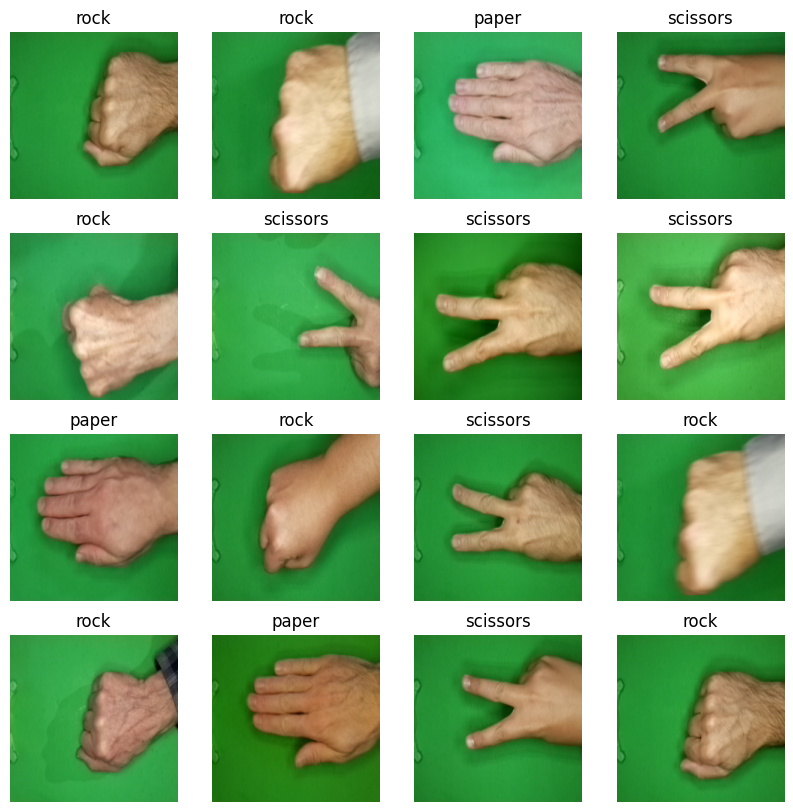

In [8]:
for imgs, labs in train_ds.take(1):
  break

# (imgs, labs) = train_ds.take(1)
plt.figure(figsize=(10, 10))
for i in range(16):
  ax = plt.subplot(4, 4, i + 1)
  plt.imshow(imgs[i].numpy().astype(np.uint8))
  plt.axis("off")
  plt.title(class_names[labs[i]])

plt.show()

In [9]:
normalization_layer = keras.layers.Rescaling(1/255.)

def preprocess_image(x,y):
  x = tf.image.resize(x, [IMG_HEIGHT, IMG_WIDTH])
  x = normalization_layer(x)
  return x, y

In [10]:
train_ds = train_ds.map(preprocess_image)
val_ds = val_ds.map(preprocess_image)

In [11]:
train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [23]:
base = keras.applications.EfficientNetV2B0(
    weights="imagenet",
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    classifier_activation="softmax",
    name="efficientnetv2-b0",)

In [24]:
base.trainalbe = False

#필요한 함수 정의하기

In [25]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.2),
    keras.layers.RandomZoom(0.2),
    # RandomCrop(IMG_HEIGHT, IMG_WIDTH)는 이미 이미지가 해당 크기로 조정된 경우 불필요하거나 문제를 일으킬 수 있어 제거합니다.
    # RandomGrayscale()는 채널 수를 변경하여 'cycle' 오류를 발생시키므로 제거합니다.
    keras.layers.RandomShear(0.2), # 전단(shear) 변형을 위해 factor 추가
    keras.layers.RandomTranslation(height_factor=0.2, width_factor=0.2), # 이동(translation) 변형을 위해 factor 추가
    keras.layers.RandomContrast(0.2), # 대비(contrast) 변형을 위해 factor 추가
])

In [26]:
def apply_rescaling(image, label):
  return normalization_layer(image), label

def apply_augmentation(image, label):
  return data_augmentation(image), label

In [27]:
model = keras.Sequential([
    base,
    keras.layers.Flatten(),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(3, activation='softmax') # 클래스 개수에 맞게 3으로 수정
])

In [28]:
train_ds = train_ds.cache().shuffle(buffer_size=1024).map(lambda image, label: apply_augmentation(image, label), num_parallel_calls=tf.data.AUTOTUNE)

In [29]:
val_ds_e = val_ds.map(apply_rescaling, num_parallel_calls=tf.data.AUTOTUNE)

In [30]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
EPOCH = 42
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCH
)

Epoch 1/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.5552 - loss: 1.0736 - val_accuracy: 0.2998 - val_loss: 1.0990
Epoch 2/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - accuracy: 0.8884 - loss: 0.9024 - val_accuracy: 0.3387 - val_loss: 1.0996
Epoch 3/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.8916 - loss: 0.7265 - val_accuracy: 0.3387 - val_loss: 1.1047
Epoch 4/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 131ms/step - accuracy: 0.8552 - loss: 0.6361 - val_accuracy: 0.2975 - val_loss: 1.1099
Epoch 5/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.9367 - loss: 0.4476 - val_accuracy: 0.3387 - val_loss: 1.2790
Epoch 6/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 129ms/step - accuracy: 0.9283 - loss: 0.3946 - val_accuracy: 0.3387 - val_loss: 1.2251
Epoch 7/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 131ms/step - accuracy: 0.9393 - loss: 0.3317 - val_accuracy: 0.4005 - val_loss: 1.1155
Epoch 8/42
35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.9432 - loss: 0.2907 - val_accuracy: 0.5

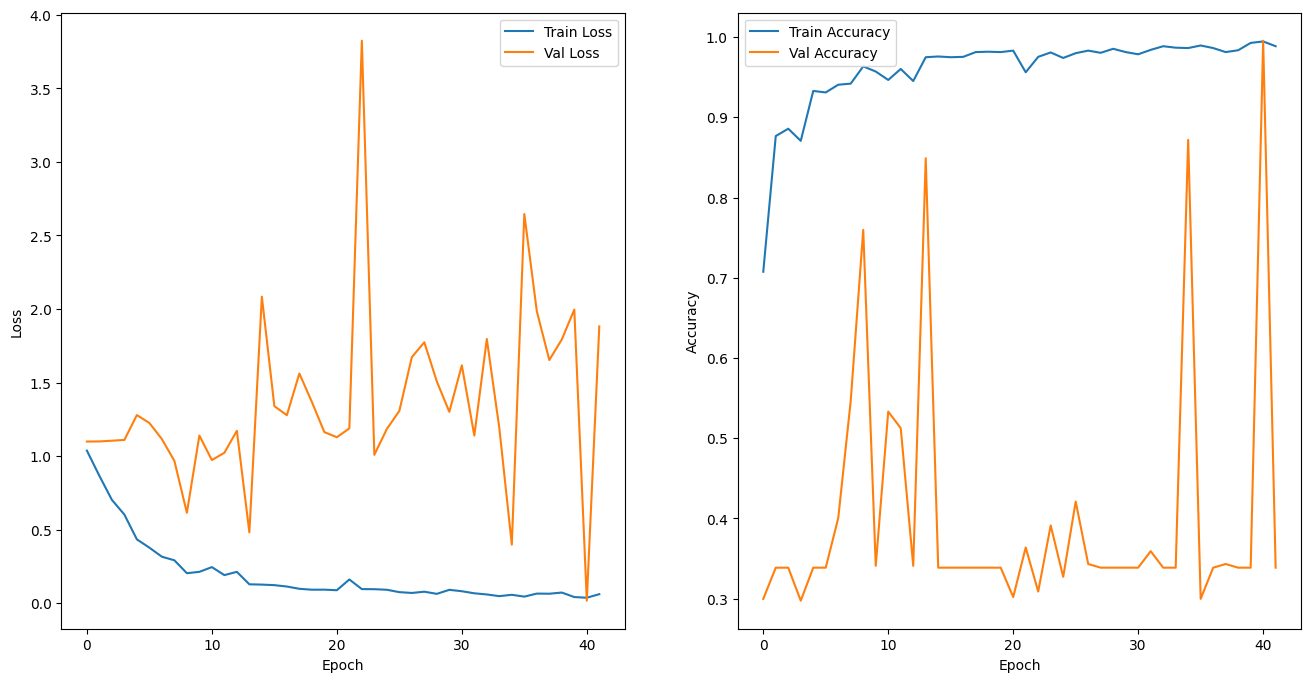

In [32]:
def plot_history(history):
  hist = pd.DataFrame(history.history)
  hist['epoch'] = history.epoch

  plt.figure(figsize=(16,8))

  plt.subplot(1,2,1)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.plot(hist['epoch'], hist['loss'],label='Train Loss')
  plt.plot(hist['epoch'], hist['val_loss'], label = 'Val Loss')
  plt.legend()

  plt.subplot(1,2,2)
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  # Corrected 'acc' to 'accuracy' and 'val_acc' to 'val_accuracy'
  plt.plot(hist['epoch'], hist['accuracy'], label='Train Accuracy')
  plt.plot(hist['epoch'], hist['val_accuracy'], label = 'Val Accuracy')

  plt.legend()
  plt.show()

plot_history(history)